# Chapitre 7 - Cours 5 : pourquoi sharder ? Avantages, inconvénients et multi-location

Les cours 1 à 4 ont répondu à la question « comment sharder ? ». Ce dernier cours prend
du recul et pose deux questions que la 2e édition du livre traite en ouverture du
chapitre : **faut-il sharder**, et à quel prix ? Et le sharding peut-il servir à autre
chose qu'à passer à l'échelle, en particulier à **isoler les clients** d'un logiciel
multi-locataire (SaaS) ? Il couvre les sections *Pros and Cons of Sharding* et
*Sharding for Multitenancy*.

**Plan.**

1. Quand une seule machine suffit : ordres de grandeur.
2. Ce que le sharding apporte : des écritures qui passent à l'échelle.
3. Le prix : clé de partitionnement et transactions multi-shards.
4. Sharder à l'intérieur d'une machine : un processus par cœur.
5. Multi-location : un locataire, un shard ?
6. Isolation : voisin bruyant, permissions et architecture cellulaire.
7. Sauvegarde, effacement, résidence et migrations progressives.
8. Les difficultés : locataires qui grandissent, géants et requêtes transverses.

In [1]:
import sqlite3
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia import partitioning_tenants as T
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Quand une seule machine suffit (section *Pros and Cons of Sharding*)

**Le problème.** Le sharding est la principale technique de **mise à l'échelle
horizontale** (*scale-out*) : au lieu d'acheter une machine plus grosse, on répartit les
données et les écritures sur plusieurs machines plus modestes, chacune responsable d'une
part à peu près égale. Mais le livre insiste sur un point souvent oublié : c'est une
solution **lourde**, qui ne se justifie qu'à grande échelle. La réplication, elle, est
utile à toute taille (tolérance aux pannes, lectures locales) ; le sharding ajoute de la
complexité dont on se passe volontiers tant qu'une seule machine tient la charge.

Or « une seule machine » est une quantité qui a beaucoup grandi. Un serveur haut de gamme
actuel compte des centaines de cœurs, plusieurs téraoctets de mémoire et des dizaines,
voire une centaine de téraoctets de SSD NVMe. Comparons ces limites à quelques charges
typiques (ordres de grandeur indicatifs, à remplacer par vos chiffres), puis calculons
combien d'années une charge qui croît de $g$ % par an met à dépasser la machine :
$t = \ln(C / V_0) / \ln(1 + g)$.

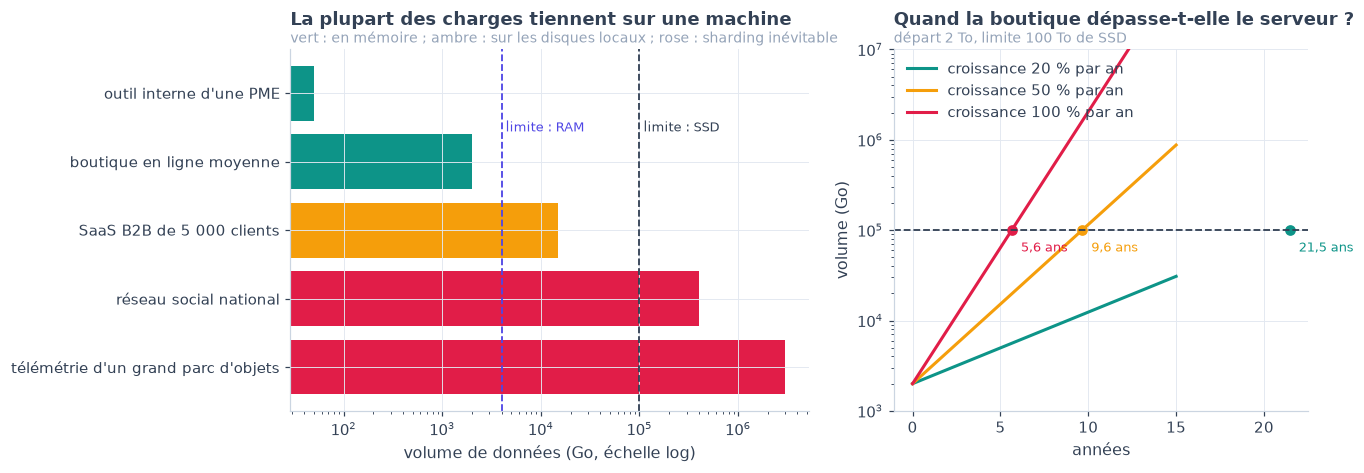

In [2]:
charges = pd.DataFrame({
    "charge": ["outil interne d'une PME", "boutique en ligne moyenne", "SaaS B2B de 5 000 clients",
               "réseau social national", "télémétrie d'un grand parc d'objets"],
    "donnees_Go": [50, 2_000, 15_000, 400_000, 3_000_000],
})
LIM_RAM, LIM_DISQUE = 4_000, 100_000          # Go : mémoire et SSD d'un gros serveur

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
cols = [TEAL if v < LIM_RAM else (AMBER if v < LIM_DISQUE else ROSE) for v in charges.donnees_Go]
ax1.barh(charges.charge, charges.donnees_Go, color=cols)
ax1.set_xscale("log")
ax1.axvline(LIM_RAM, color=INDIGO, ls="--", lw=1.2)
ax1.axvline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax1.text(LIM_RAM * 1.1, 0.5, "limite : RAM", color=INDIGO, fontsize=8.5, va="center")
ax1.text(LIM_DISQUE * 1.1, 0.5, "limite : SSD", color=SLATE, fontsize=8.5, va="center")
ax1.invert_yaxis()
ax1.set_xlabel("volume de données (Go, échelle log)")
ax1.set_title("La plupart des charges tiennent sur une machine")
subtitle(ax1, "vert : en mémoire ; ambre : sur les disques locaux ; rose : sharding inévitable")

V0 = 2_000
for g, c in [(0.2, TEAL), (0.5, AMBER), (1.0, ROSE)]:
    years = np.arange(0, 16)
    ax2.plot(years, V0 * (1 + g) ** years, color=c, label=f"croissance {g:.0%} par an".replace("%", " %"))
    t_cross = np.log(LIM_DISQUE / V0) / np.log(1 + g)
    ax2.plot([t_cross], [LIM_DISQUE], "o", color=c)
    ax2.annotate(f"{t_cross:.1f} ans".replace(".", ","), (t_cross, LIM_DISQUE), (6, -14),
                 textcoords="offset points", fontsize=8.5, color=c)
ax2.axhline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax2.set_yscale("log")
ax2.set_ylim(1e3, 1e7)
ax2.set_xlabel("années")
ax2.set_ylabel("volume (Go)")
ax2.set_title("Quand la boutique dépasse-t-elle le serveur ?")
subtitle(ax2, "départ 2 To, limite 100 To de SSD")
ax2.legend(loc="upper left")
finish(fig)
plt.show()

Avec 2 To aujourd'hui, une boutique qui croît de 20 % par an dispose de plus de vingt
ans de marge ; même à 50 % par an, il lui reste presque une décennie. Le livre en tire
une recommandation nette : tant que le volume et le **débit d'écriture** tiennent sur un
nœud, mieux vaut rester sur une base à un seul shard (répliquée pour la tolérance aux
pannes) et garder la simplicité. Ce raisonnement est volontairement optimiste : il ne
tient compte ni du débit d'écriture (souvent la vraie limite, section suivante), ni du
temps de reconstruction d'un nœud de 100 To après une panne, qui peut lui aussi pousser à
découper plus tôt.

> **À retenir.** Le sharding se justifie quand les données ou les écritures dépassent
> ce qu'un nœud peut porter. Une machine actuelle porte beaucoup : vérifiez les ordres de
> grandeur avant de payer la complexité du sharding.

## 2. Ce que le sharding apporte : des écritures qui passent à l'échelle (section *Pros and Cons of Sharding*)

Si c'est le débit de **lecture** qui sature, le chapitre 6 offre une
réponse plus simple : ajouter des suiveurs qui servent les lectures. Mais chaque suiveur
doit rejouer **toutes** les écritures : la réplication multiplie la capacité de lecture,
pas celle d'écriture. Le sharding, lui, découpe aussi les écritures : avec $n$ shards
équilibrés, chaque nœud n'en reçoit que $1/n$.

Modélisons un nœud capable de 20 000 opérations par seconde et une charge composée à 90 %
de lectures. Avec $r$ suiveurs, chaque nœud consacre une part de sa capacité à appliquer
le flux d'écritures complet ; avec $n$ shards (chacun répliqué, mais servant sa part),
les écritures se partagent.

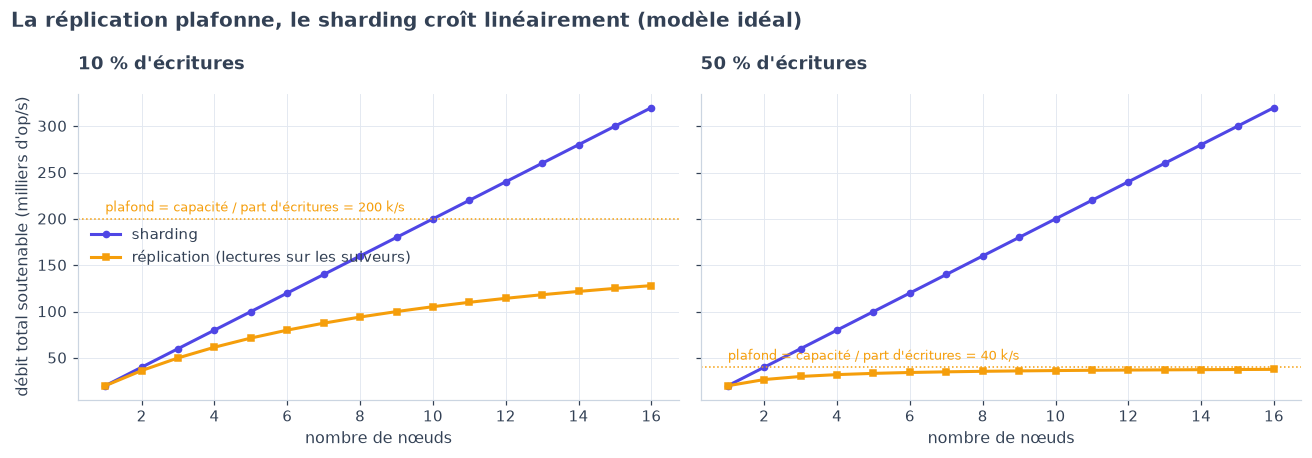

In [3]:
CAP = 20_000                       # opérations/s par nœud
nodes = np.arange(1, 17)

def capacity_replicas(n, write_frac):
    # tous les nœuds appliquent toutes les écritures ; les lectures se répartissent.
    # débit total X : écritures w = f X appliquées n fois, lectures (1 - f) X réparties
    # contrainte par nœud : f X + (1 - f) X / n <= CAP
    return CAP / (write_frac + (1 - write_frac) / n)

def capacity_shards(n, write_frac):
    return CAP * n                  # chaque opération ne touche qu'un shard

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, wf in zip(axes, [0.1, 0.5]):
    xr = capacity_replicas(nodes, wf)
    xs = capacity_shards(nodes, wf)
    ax.plot(nodes, xs / 1e3, color=INDIGO, marker="o", ms=4, label="sharding")
    ax.plot(nodes, xr / 1e3, color=AMBER, marker="s", ms=4, label="réplication (lectures sur les suiveurs)")
    ax.axhline(CAP / wf / 1e3, color=AMBER, ls=":", lw=1)
    ax.text(1, CAP / wf / 1e3 + 8, f"plafond = capacité / part d'écritures = {CAP / wf / 1e3:.0f} k/s",
            ha="left", color=AMBER, fontsize=8.5)
    ax.set_xlabel("nombre de nœuds")
    ax.set_title(f"{wf:.0%} d'écritures".replace("%", " %"))
axes[0].set_ylabel("débit total soutenable (milliers d'op/s)")
axes[0].legend(loc="center left")
finish(fig, "La réplication plafonne, le sharding croît linéairement (modèle idéal)")
plt.show()

Avec 10 % d'écritures, la réplication plafonne à dix fois la capacité d'un nœud ; avec
50 %, au double. Le sharding croît linéairement, **dans le cas idéal** où les shards
sont équilibrés et où chaque opération ne touche qu'un shard. Les cours 2 et 3 ont montré
ce que coûte le déséquilibre ; la section suivante chiffre la seconde hypothèse.

> **À retenir.** Réplication et sharding se complètent : la première multiplie les
> lectures et apporte la tolérance aux pannes, le second est le seul des deux qui
> multiplie la capacité d'**écriture** et de **stockage**.

## 3. Le prix : clé de partitionnement et transactions multi-shards (section *Pros and Cons of Sharding*)

Sharder impose de choisir une **clé de partitionnement** : tous les enregistrements de
même clé vont dans le même shard. Accéder à un enregistrement dont on connaît la clé est
rapide ; tout le reste (recherche par un autre attribut, jointure, mise à jour de
plusieurs enregistrements) risque de toucher plusieurs shards. Et ce choix est **difficile
à changer** une fois les données en place.

Le cas le plus coûteux est la transaction qui écrit dans plusieurs shards : elle exige
une **transaction distribuée** (validation en deux phases, chapitre 8),
bien plus lente qu'une transaction locale. Si une transaction touche $k$ enregistrements
placés au hasard parmi $n$ shards, la probabilité qu'ils tombent tous dans le même shard
vaut $(1/n)^{k-1}$ : elle s'effondre dès $k = 2$.

In [4]:
ks = np.arange(1, 7)
rows = []
for n in [2, 4, 16, 64]:
    rows.append([T.single_shard_probability(n, k) for k in ks])
tab = pd.DataFrame(rows, index=[f"{n} shards" for n in [2, 4, 16, 64]],
                   columns=[f"k = {k}" for k in ks])
print("Probabilité qu'une transaction sur k enregistrements aléatoires reste sur un seul shard :")
tab.map(lambda v: f"{v:.1%}".replace(".", ","))

Probabilité qu'une transaction sur k enregistrements aléatoires reste sur un seul shard :


,k = 1,k = 2,k = 3,k = 4,k = 5,k = 6
2 shards,"100,0%","50,0%","25,0%","12,5%","6,2%","3,1%"
4 shards,"100,0%","25,0%","6,2%","1,6%","0,4%","0,1%"
16 shards,"100,0%","6,2%","0,4%","0,0%","0,0%","0,0%"
64 shards,"100,0%","1,6%","0,0%","0,0%","0,0%","0,0%"


Avec 16 shards, une transaction qui touche deux enregistrements quelconques n'a qu'une
chance sur seize d'être locale. Tout l'art du choix de la clé consiste à faire que les
enregistrements écrits ensemble partagent la même clé : par exemple, toutes les lignes
d'une commande et le compte du client sous la clé « client ». Chiffrons l'enjeu avec un
petit modèle de latence :

- transaction **locale** : exécution (0,5 ms) puis écriture durable du journal (`fsync`,
  environ 1 ms) ;
- transaction **distribuée** : exécution, aller-retour vers les participants (0,5 ms),
  phase de préparation (aller-retour + `fsync` sur chaque participant, on attend le plus
  lent), journalisation de la décision par le coordinateur (`fsync`), phase de validation
  (aller-retour).

Les durées de `fsync` sont tirées selon une loi log-normale (queue lourde), ce qui
pénalise la transaction distribuée deux fois : elle cumule les étapes **et** attend le
participant le plus lent.

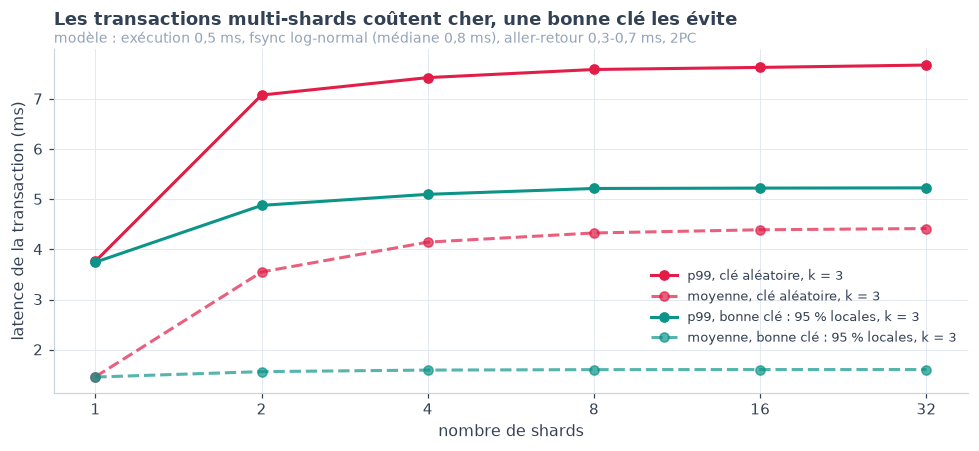

multi                       \
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3   
shards                                                          
1                                   0.00                 0.00   
2                                   0.04                 0.75   
4                                   0.05                 0.94   
8                                   0.05                 0.98   
16                                  0.05                 1.00   
32                                  0.05                 1.00   

                                 moyenne                       \
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3   
shards                                                          
1                                   1.45                 1.46   
2                                   1.56                 3.55   
4                                   1.59                 4.15   
8                                   1.60                 4.33   
16                                  1.60                 4.39   
32                                  1.60                 4.42   

                                     p99                       
scénario bonne clé : 95 % locales, k = 3 clé aléatoire, k = 3  
shards                                                         
1                                   3.75                 3.76  
2                                   4.88                 7.08  
4                                   5.10                 7.43  
8                                   5.21                 7.59  
16                                  5.22                 7.63  
32                                  5.23                 7.68

In [5]:
def txn_latency(n_shards, k, n_txn=40_000, local_frac=None, seed=0):
    """Latence (ms) de transactions sur k enregistrements ; local_frac : part forcée sur un seul shard."""
    r = np.random.default_rng(seed)
    shards = r.integers(0, n_shards, size=(n_txn, k))
    if local_frac is not None:
        loc = r.random(n_txn) < local_frac
        shards[loc] = shards[loc, :1]
    n_part = np.array([len(set(row)) for row in shards])
    fsync = lambda size: r.lognormal(np.log(0.8), 0.6, size)
    rtt = lambda size: r.uniform(0.3, 0.7, size)
    single = 0.5 + fsync(n_txn)
    prepare = rtt(n_txn) + np.array([fsync(m).max() for m in n_part])
    distributed = 0.5 + rtt(n_txn) + prepare + fsync(n_txn) + rtt(n_txn)
    return np.where(n_part == 1, single, distributed), n_part

res = []
for n in [1, 2, 4, 8, 16, 32]:
    for label, kw in [("clé aléatoire, k = 3", dict(k=3)),
                      ("bonne clé : 95 % locales, k = 3", dict(k=3, local_frac=0.95))]:
        lat, npart = txn_latency(n, **kw)
        res.append({"shards": n, "scénario": label, "moyenne": lat.mean(), "p99": np.percentile(lat, 99),
                    "multi": np.mean(npart > 1)})
res = pd.DataFrame(res)

fig, ax = plt.subplots(figsize=(9, 4.2))
for (label, g), c in zip(res.groupby("scénario", sort=False), [ROSE, TEAL]):
    ax.plot(g.shards, g.p99, color=c, marker="o", label=f"p99, {label}")
    ax.plot(g.shards, g.moyenne, color=c, marker="o", ls="--", alpha=0.7, label=f"moyenne, {label}")
ax.set_xscale("log", base=2)
ax.set_xticks([1, 2, 4, 8, 16, 32]); ax.set_xticklabels([1, 2, 4, 8, 16, 32])
ax.set_xlabel("nombre de shards")
ax.set_ylabel("latence de la transaction (ms)")
ax.set_title("Les transactions multi-shards coûtent cher, une bonne clé les évite")
subtitle(ax, "modèle : exécution 0,5 ms, fsync log-normal (médiane 0,8 ms), aller-retour 0,3-0,7 ms, 2PC")
ax.legend(fontsize=8.5, loc="center right", bbox_to_anchor=(1.0, 0.25))
plt.tight_layout(); plt.show()
res.pivot(index="shards", columns="scénario", values=["multi", "moyenne", "p99"]).round(2)

Le tableau confirme l'intuition : avec une clé aléatoire, la part de transactions
multi-shards passe de 75 % (2 shards) à presque 100 %, et la latence moyenne est
multipliée par deux à trois par rapport à une base unique ; le p99, qui attend le
participant le plus lent, se dégrade encore à mesure que la transaction touche plus de
participants. Avec une clé qui rend 95 % des transactions locales, la moyenne reste
proche de celle d'un seul nœud. Ce modèle ignore en plus l'essentiel du coût réel : les
verrous tenus pendant les deux phases, qui réduisent le débit des enregistrements
chauds, et la fragilité face à la panne du coordinateur (chapitre 8).

Le même raisonnement vaut pour les requêtes : le sharding se marie bien avec les données
clé-valeur, beaucoup moins avec le relationnel où l'on cherche par index secondaire
(cours 4) et où l'on joint des enregistrements qui vivent sur des shards différents.

> **À retenir.** Le sharding se paie en accès multi-shards : recherches dispersées,
> jointures distantes et transactions distribuées. Le choix de la clé de
> partitionnement décide de la part de ces opérations ; il faut le faire tôt, car il est
> difficile à défaire.

## 4. Sharder à l'intérieur d'une machine : un processus par cœur (section *Pros and Cons of Sharding*)

Le sharding n'est pas réservé aux clusters. Certains systèmes (le livre cite Redis,
VoltDB et FoundationDB) l'appliquent **dans une seule machine** : un processus monothread
par cœur, chacun propriétaire d'une partie des données. Deux raisons :

- **pas de verrous partagés** : un processus monothread n'a pas besoin de se synchroniser
  avec les autres pour accéder à ses données, il évite la contention sur les structures
  communes ;
- **NUMA** (*nonuniform memory access*) : dans un serveur à plusieurs sockets, chaque
  processeur a sa banque de mémoire « proche » ; accéder à celle d'un autre socket coûte
  sensiblement plus cher. Un shard dont les données vivent dans la mémoire proche de son
  cœur ne paie jamais ce surcoût.

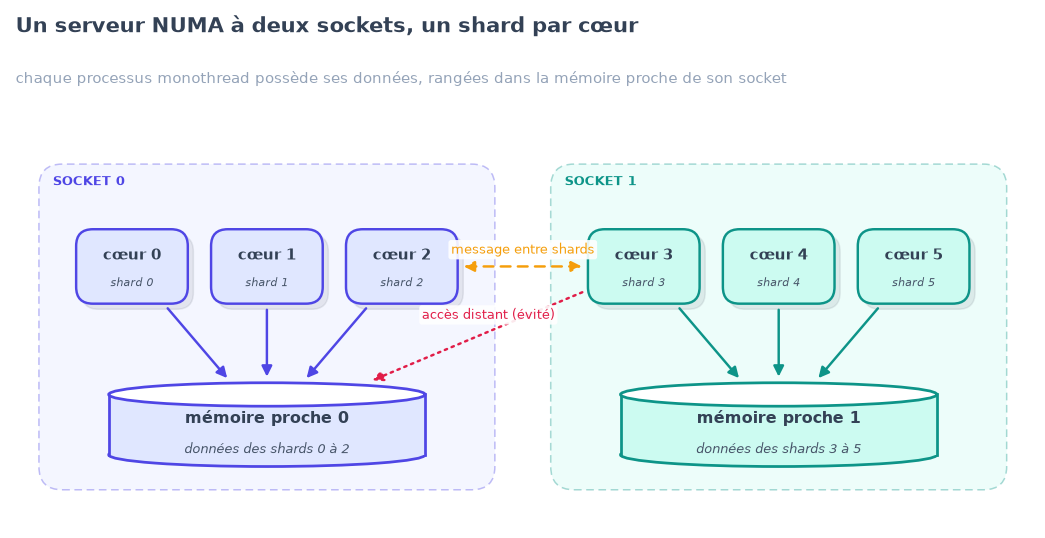

In [6]:
d = Diagram(11, 4.6, title="Un serveur NUMA à deux sockets, un shard par cœur",
            subtitle="chaque processus monothread possède ses données, rangées dans la mémoire proche de son socket")
d.group(0.3, 0.4, 5.2, 3.9, "socket 0", color=INDIGO)
d.group(5.8, 0.4, 10.7, 3.9, "socket 1", color=TEAL)
for i, x in enumerate([1.3, 2.75, 4.2]):
    d.box(f"c{i}", x, 2.8, f"cœur {i}", sub=f"shard {i}", color=INDIGO, w=1.2, h=0.8, fontsize=9.5)
for i, x in enumerate([6.8, 8.25, 9.7]):
    d.box(f"c{i + 3}", x, 2.8, f"cœur {i + 3}", sub=f"shard {i + 3}", color=TEAL, w=1.2, h=0.8, fontsize=9.5)
d.box("m0", 2.75, 1.1, "mémoire proche 0", sub="données des shards 0 à 2", color=INDIGO, kind="db", w=3.4, h=0.9)
d.box("m1", 8.25, 1.1, "mémoire proche 1", sub="données des shards 3 à 5", color=TEAL, kind="db", w=3.4, h=0.9)
for i in range(3):
    d.arrow(f"c{i}", "m0", color=INDIGO)
    d.arrow(f"c{i + 3}", "m1", color=TEAL)
d.arrow("c2", "c3", "message entre shards", style="dashed", color=AMBER, both=True)
d.arrow("c3", "m0", "accès distant (évité)", style="dotted", color=ROSE, label_pos=0.45)
d.show()

Un modèle de débit simple montre l'intérêt et la limite de l'approche. Une base
multithread classique protège ses structures communes par des verrous : une fraction
$\sigma$ du travail est sérialisée, et le débit suit la loi d'Amdahl
$X(n) = n / (1 + \sigma (n - 1))$. Avec un shard par cœur, il n'y a rien à sérialiser,
mais une opération qui touche deux shards doit envoyer un message à un autre cœur et
coûte $c$ fois plus cher : si une fraction $f$ des opérations est multi-shards,
$X(n) = n / (1 + f c)$.

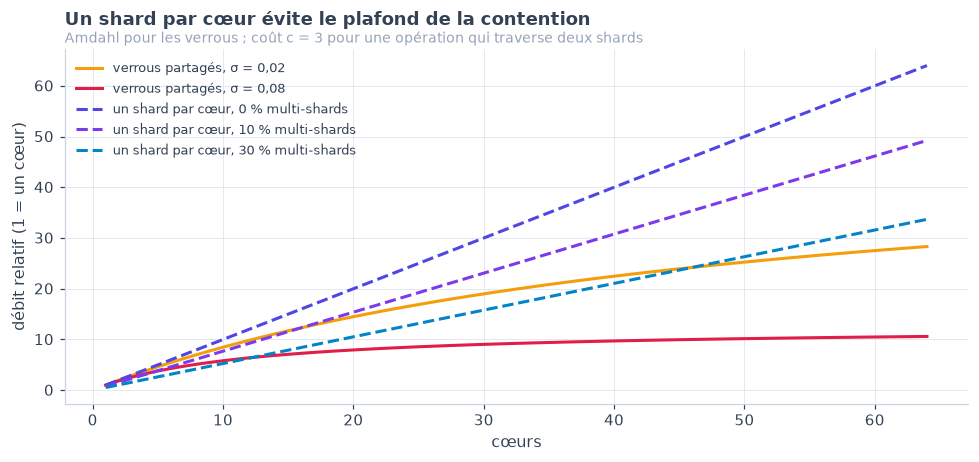

In [7]:
cores = np.arange(1, 65)
fig, ax = plt.subplots(figsize=(9, 4.3))
for sigma, c in [(0.02, AMBER), (0.08, ROSE)]:
    ax.plot(cores, cores / (1 + sigma * (cores - 1)), color=c, label=f"verrous partagés, σ = {sigma:.2f}".replace(".", ","))
for f, c in [(0.0, INDIGO), (0.1, VIOLET), (0.3, SKY)]:
    ax.plot(cores, cores / (1 + f * 3), color=c, ls="--", label=f"un shard par cœur, {f:.0%} multi-shards".replace("%", " %"))
ax.set_xlabel("cœurs")
ax.set_ylabel("débit relatif (1 = un cœur)")
ax.set_title("Un shard par cœur évite le plafond de la contention")
subtitle(ax, "Amdahl pour les verrous ; coût c = 3 pour une opération qui traverse deux shards")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec 2 % de travail sérialisé, la base à verrous plafonne vers 28 fois un cœur à 64
cœurs ; avec 8 %, vers 11. Le découpage par cœur croît linéairement, avec une pente
réduite par les opérations multi-shards : on retrouve en miniature, à l'intérieur d'une
machine, le compromis de la section 3.

> **À retenir.** Un shard par cœur remplace la synchronisation par des messages : la
> contention disparaît, mais les opérations qui traversent plusieurs shards deviennent
> plus chères. Le sharding est un outil de parallélisme, pas seulement de capacité.

## 5. Multi-location : un locataire, un shard ? (section *Sharding for Multitenancy*)

Un logiciel en ligne (SaaS) sert généralement de nombreux **locataires** (*tenants*) :
chaque entreprise cliente a ses utilisateurs, mais ses données forment un ensemble
autonome, séparé de celui des autres. Dans un service d'envoi de lettres d'information,
les abonnés et les statistiques d'un client ne concernent que lui. Le locataire est donc
une clé de partitionnement naturelle : on peut donner un shard à chaque locataire, ou
regrouper plusieurs petits locataires dans un même shard. Ces shards peuvent être des
bases physiquement séparées (une base embarquée par locataire, comme SQLite, chapitre
4) ou des portions administrables séparément d'une grande base logique.

Le premier fait à connaître est la **distribution des tailles** : elle est très
asymétrique. Simulons 2 000 locataires dont la taille suit une loi log-normale (médiane
2 Go), puis rangeons-les dans des shards de 500 Go par l'heuristique *first-fit
decreasing* (du plus gros au plus petit, chacun dans le premier shard où il tient).

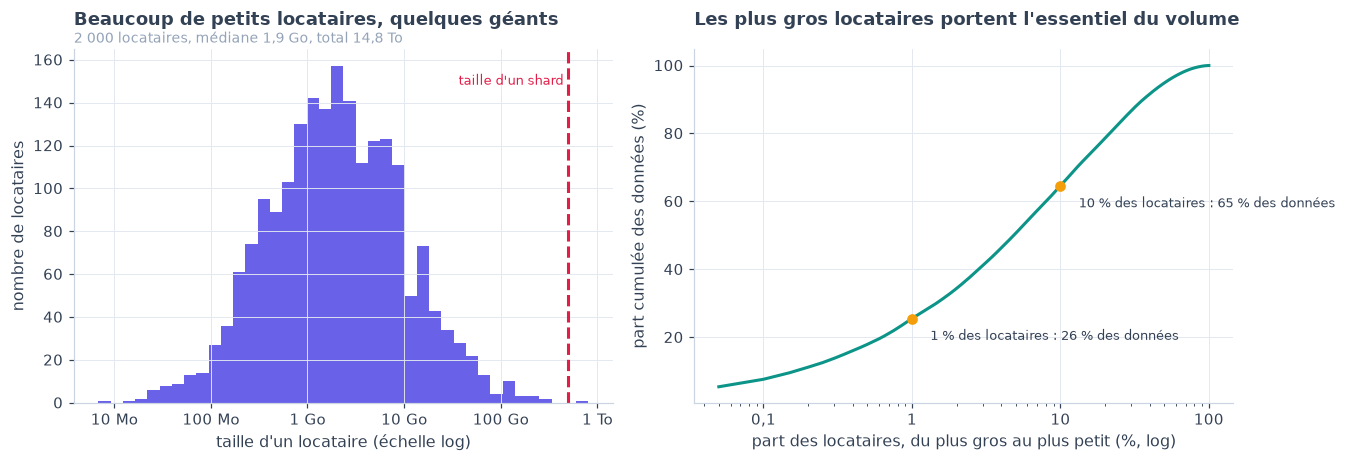

,stratégie,shards,remplissage moyen,locataires trop gros pour un shard
0,un shard par locataire,2000,0.015,1
1,first-fit decreasing (500 Go),30,0.967,1


In [8]:
sizes = T.tenant_sizes(2_000, median=2.0, sigma=1.6, seed=1)
CAPA = 500.0
bins, giants = T.pack_tenants(sizes, CAPA)
fill = np.array([sizes[b].sum() / CAPA for b in bins])
order = np.sort(sizes)[::-1]
share = np.cumsum(order) / order.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax1.hist(np.log10(sizes), bins=40, color=INDIGO, alpha=0.85)
ax1.set_xticks([-2, -1, 0, 1, 2, 3]); ax1.set_xticklabels(["10 Mo", "100 Mo", "1 Go", "10 Go", "100 Go", "1 To"])
ax1.axvline(np.log10(CAPA), color=ROSE, ls="--")
ax1.text(np.log10(CAPA) - 0.05, ax1.get_ylim()[1] * 0.9, "taille d'un shard", color=ROSE, ha="right", fontsize=8.5)
ax1.set_xlabel("taille d'un locataire (échelle log)")
ax1.set_ylabel("nombre de locataires")
ax1.set_title("Beaucoup de petits locataires, quelques géants")
subtitle(ax1, f"2 000 locataires, médiane {np.median(sizes):.1f} Go, total {sizes.sum() / 1e3:.1f} To".replace(".", ","))

pct = np.arange(1, sizes.size + 1) / sizes.size * 100
ax2.plot(pct, share * 100, color=TEAL)
for p in [1, 10]:
    v = share[int(sizes.size * p / 100) - 1] * 100
    ax2.plot([p], [v], "o", color=AMBER)
    ax2.annotate(f"{p} % des locataires : {v:.0f} % des données", (p, v), (12, -14), textcoords="offset points",
                 fontsize=8.5, color=SLATE)
ax2.set_xscale("log")
ax2.set_xticks([0.1, 1, 10, 100]); ax2.set_xticklabels(["0,1", "1", "10", "100"])
ax2.set_xlabel("part des locataires, du plus gros au plus petit (%, log)")
ax2.set_ylabel("part cumulée des données (%)")
ax2.set_title("Les plus gros locataires portent l'essentiel du volume")
finish(fig)
plt.show()

pd.DataFrame({
    "stratégie": ["un shard par locataire", "first-fit decreasing (500 Go)"],
    "shards": [sizes.size, len(bins) + len(giants)],
    "remplissage moyen": [sizes.mean() / CAPA, fill.mean()],
    "locataires trop gros pour un shard": [len(giants), len(giants)],
})

Les chiffres racontent les deux extrêmes du problème :

- un shard par locataire signifierait 2 000 shards remplis en moyenne à 1,5 % : chaque
  shard a un coût fixe (processus, connexions, réplication, sauvegardes, supervision),
  payé 2 000 fois pour des locataires qui pèsent pour la plupart quelques gigaoctets ;
- le rangement regroupe les petits locataires en une trentaine de shards remplis à plus
  de 95 % en moyenne ;
- et un locataire pèse à lui seul plus qu'un shard entier : pour lui, la multi-location
  ne suffit pas, il faut **le sharder lui-même**, ce qui nous ramène au sharding pour la
  scalabilité des cours 1 à 4 (section 8).

> **À retenir.** Le locataire est une clé de partitionnement naturelle, mais la taille
> des locataires suit une loi très asymétrique : on regroupe les petits, on isole (et
> parfois on découpe) les gros.

## 6. Isolation : voisin bruyant, permissions et architecture cellulaire (section *Sharding for Multitenancy*)

Le livre énumère plusieurs avantages du sharding par locataire. Les trois premiers
relèvent de l'**isolation**.

**Isolation des ressources.** Si un locataire lance une opération coûteuse (un export
massif, une requête analytique), seuls ses voisins **de shard** en souffrent. Mesurons-le
avec `noisy_neighbor_slowdown` : chaque shard est modélisé par une file M/M/1, chaque
locataire apporte une petite charge, et l'un d'eux ajoute soudain une charge égale à 40 %
de la capacité d'un shard. On fait varier le nombre de locataires par shard, la charge
moyenne de chaque shard restant fixée à 50 %.

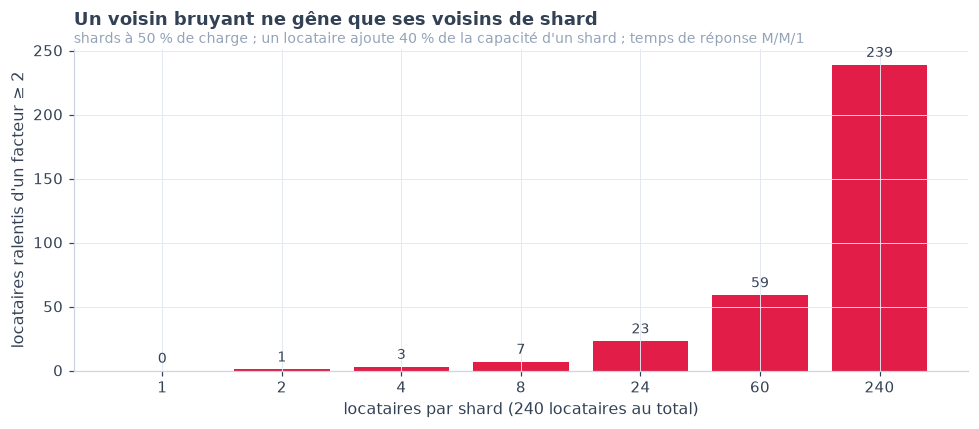

,locataires par shard,shards,victimes ralenties ×2 ou plus,ralentissement des voisins
0,1,240,0,1.0
1,2,120,1,5.0
2,4,60,3,5.0
3,8,30,7,5.0
4,24,10,23,5.0
5,60,4,59,5.0
6,240,1,239,5.0


In [9]:
N_T = 240
rows = []
for per_shard in [1, 2, 4, 8, 24, 60, 240]:
    n_sh = N_T // per_shard
    loads = np.full(N_T, 0.5 / per_shard)
    shard_of = np.repeat(np.arange(n_sh), per_shard)
    slow = T.noisy_neighbor_slowdown(loads, shard_of, heavy=0, extra=0.4)
    victims = np.delete(slow, 0)
    rows.append({"locataires par shard": per_shard, "shards": n_sh,
                 "victimes ralenties ×2 ou plus": int((victims >= 2).sum()),
                 "ralentissement des voisins": float(victims.max())})
nn = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([str(v) for v in nn["locataires par shard"]], nn["victimes ralenties ×2 ou plus"], color=ROSE)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("locataires par shard (240 locataires au total)")
ax.set_ylabel("locataires ralentis d'un facteur ≥ 2")
ax.set_title("Un voisin bruyant ne gêne que ses voisins de shard")
subtitle(ax, "shards à 50 % de charge ; un locataire ajoute 40 % de la capacité d'un shard ; temps de réponse M/M/1")
plt.tight_layout(); plt.show()
nn

Dans ce modèle, le shard du locataire bruyant passe de 50 % à 90 % d'utilisation : le
temps de réponse y est multiplié par cinq, et **tous** ses voisins de shard le subissent.
Avec un locataire par shard, personne n'est touché ; avec une base unique partagée, les
239 autres le sont. Le nombre de locataires par shard est donc un curseur entre le coût
fixe (section 5) et le rayon d'impact.

**Isolation des permissions.** Le second avantage est plus subtil : il protège contre
les **bogues** du contrôle d'accès. Dans une base partagée, chaque requête doit filtrer
sur l'identifiant du locataire ; un seul oubli expose les données de tout le monde. Si
chaque locataire a sa propre base, la même erreur ne peut renvoyer que ses propres
données. Démonstration avec SQLite :

In [10]:
tmp = Path(tempfile.mkdtemp())
clients = ["acme", "globex", "initech"]

shared = sqlite3.connect(":memory:")
shared.execute("CREATE TABLE abonnes (tenant TEXT, email TEXT)")
per_tenant = {}
for t in clients:
    per_tenant[t] = sqlite3.connect(tmp / f"{t}.db")
    per_tenant[t].execute("CREATE TABLE IF NOT EXISTS abonnes (email TEXT)")
    per_tenant[t].execute("DELETE FROM abonnes")
    for i in range(3):
        shared.execute("INSERT INTO abonnes VALUES (?, ?)", (t, f"client{i}@{t}.example"))
        per_tenant[t].execute("INSERT INTO abonnes VALUES (?)", (f"client{i}@{t}.example",))
    per_tenant[t].commit()

def liste_abonnes_boguee(con, tenant):
    # bogue : le développeur a oublié « WHERE tenant = ? »
    return [r[-1] for r in con.execute("SELECT * FROM abonnes")]

print("base partagée, requête de acme :", liste_abonnes_boguee(shared, "acme"))
print("base par locataire, requête de acme :", liste_abonnes_boguee(per_tenant["acme"], "acme"))

base partagée, requête de acme : ['client0@acme.example', 'client1@acme.example', 'client2@acme.example', 'client0@globex.example', 'client1@globex.example', 'client2@globex.example', 'client0@initech.example', 'client1@initech.example', 'client2@initech.example']
base par locataire, requête de acme : ['client0@acme.example', 'client1@acme.example', 'client2@acme.example']


Le bogue est le même ; dans la base partagée il divulgue les abonnés des concurrents,
dans la base par locataire il est inoffensif. La séparation physique transforme une
faille de confidentialité en simple défaut.

**Architecture cellulaire.** On peut pousser l'idée au-delà du stockage : dans une
*cell-based architecture*, les services applicatifs **et** le stockage d'un groupe de
locataires forment une **cellule** autonome, qui fonctionne largement indépendamment des
autres. Une panne, une surcharge ou un déploiement raté restent confinés à leur cellule.
Un routeur mince, en amont, envoie chaque requête vers la cellule de son locataire.

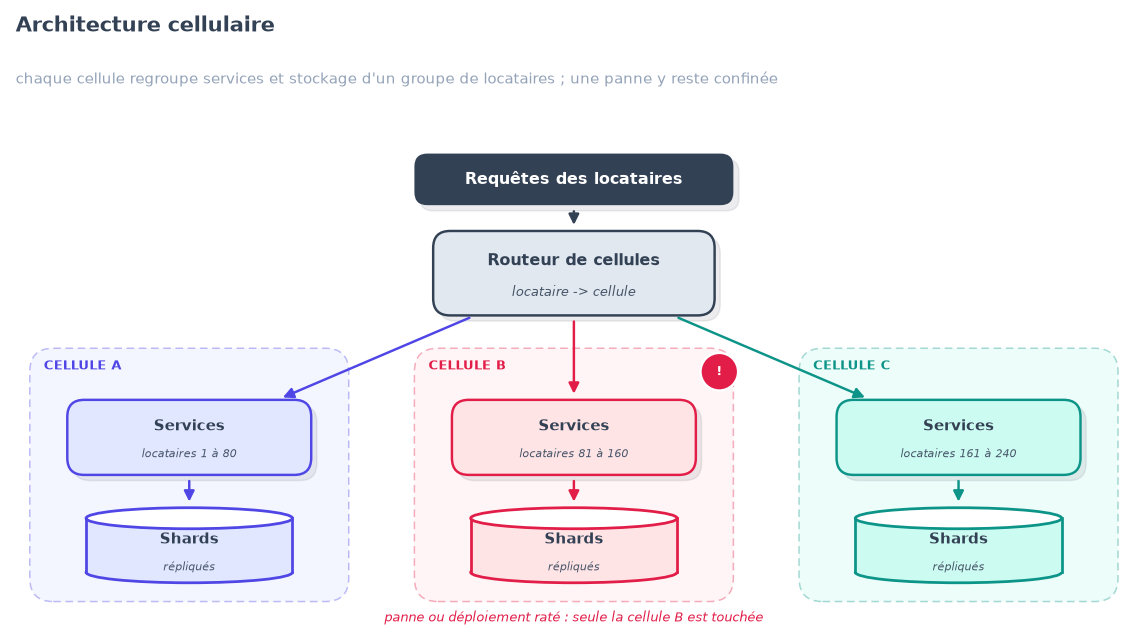

In [11]:
d = Diagram(12, 5.6, title="Architecture cellulaire",
            subtitle="chaque cellule regroupe services et stockage d'un groupe de locataires ; une panne y reste confinée")
d.box("u", 6.0, 4.75, "Requêtes des locataires", kind="tag", color=SLATE, w=3.4, h=0.55)
d.box("r", 6.0, 3.75, "Routeur de cellules", sub="locataire -> cellule", color=SLATE, w=3.0)
d.arrow("u", "r")
cells = [(1.9, "Cellule A", "locataires 1 à 80", INDIGO), (6.0, "Cellule B", "locataires 81 à 160", ROSE),
         (10.1, "Cellule C", "locataires 161 à 240", TEAL)]
for i, (x, name, sub, c) in enumerate(cells):
    d.group(x - 1.7, 0.25, x + 1.7, 2.95, name, color=c)
    d.box(f"app{i}", x, 2.0, "Services", sub=sub, color=c, w=2.6, h=0.8, fontsize=9.5)
    d.box(f"db{i}", x, 0.85, "Shards", sub="répliqués", color=c, kind="db", w=2.2, h=0.8, fontsize=9.5)
    d.arrow(f"app{i}", f"db{i}", color=c)
    d.arrow("r", f"app{i}", color=c)
d.note(6.0, 0.08, "panne ou déploiement raté : seule la cellule B est touchée", color=ROSE, fontsize=8.5)
d.badge(7.55, 2.7, "!", color=ROSE)
d.show()

Quantifions le rayon d'impact. Supposons six incidents graves par an (déploiement raté,
saturation, corruption), chacun limité à une cellule tirée au hasard. Avec $C$ cellules,
un incident touche $1/C$ des locataires, et la probabilité qu'un locataire donné subisse
au moins un incident dans l'année vaut $1 - (1 - 1/C)^6$.

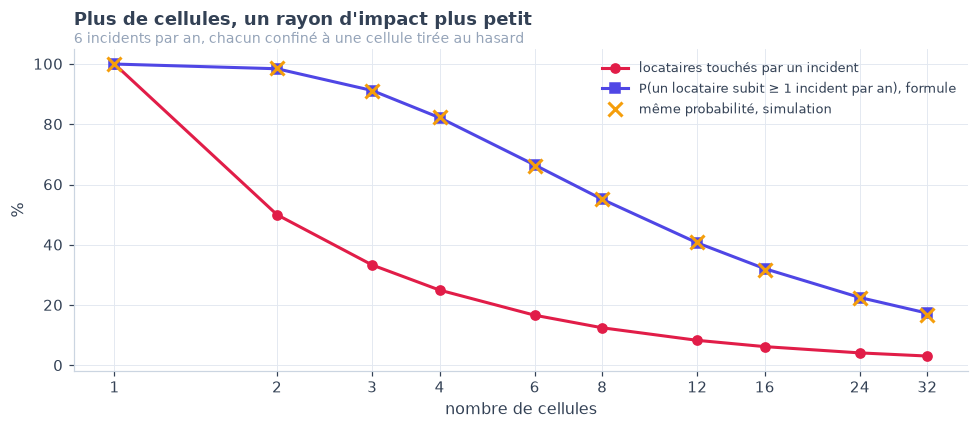

In [12]:
C = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32])
inc = 6
sim = []
r = np.random.default_rng(3)
for c in C:
    hits = r.integers(0, c, size=(20_000, inc))       # 20 000 années simulées, cellule touchée par incident
    sim.append(np.mean((hits == 0).any(axis=1)))     # le locataire étudié vit dans la cellule 0

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(C, 100 / C, color=ROSE, marker="o", label="locataires touchés par un incident")
ax.plot(C, 100 * (1 - (1 - 1 / C) ** inc), color=INDIGO, marker="s", label="P(un locataire subit ≥ 1 incident par an), formule")
ax.plot(C, 100 * np.array(sim), "x", color=AMBER, ms=9, mew=2, label="même probabilité, simulation")
ax.set_xscale("log", base=2)
ax.set_xticks(C); ax.set_xticklabels(C)
ax.set_xlabel("nombre de cellules")
ax.set_ylabel("%")
ax.set_title("Plus de cellules, un rayon d'impact plus petit")
subtitle(ax, "6 incidents par an, chacun confiné à une cellule tirée au hasard")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec une seule « cellule » (le système monolithique), chaque incident touche tout le
monde et chaque locataire en subit six par an. Avec 12 cellules, un incident touche 8 %
des locataires et un locataire donné a environ 41 % de chances d'en subir au moins un
dans l'année. Le nombre total d'incidents ne baisse pas, mais leur **rayon d'impact**
rétrécit : c'est le principe des domaines de panne du chapitre 2,
appliqué à l'application entière.

> **À retenir.** Sharder par locataire isole les ressources (un voisin bruyant ne gêne
> que son shard), les permissions (un bogue d'autorisation ne traverse pas les bases) et,
> avec une architecture cellulaire, les pannes elles-mêmes.

## 7. Sauvegarde, effacement, résidence et migrations progressives (section *Sharding for Multitenancy*)

Les avantages suivants tiennent à ce qu'un shard par locataire (ou par petit groupe) est
une **unité d'administration**.

**Sauvegarde et restauration par locataire.** Un client efface par erreur ses données :
avec une base partagée, restaurer une sauvegarde ramènerait tous les autres locataires
en arrière. Avec une base par locataire, on restaure la sienne seule. Reprenons nos bases
SQLite :

In [13]:
backup = sqlite3.connect(":memory:")
per_tenant["globex"].backup(backup)                       # sauvegarde de globex seul
per_tenant["globex"].execute("DELETE FROM abonnes")       # fausse manœuvre du client
per_tenant["globex"].commit()
per_tenant["acme"].execute("INSERT INTO abonnes VALUES ('nouveau@acme.example')")   # acme continue sa vie
per_tenant["acme"].commit()
avant = {t: per_tenant[t].execute("SELECT COUNT(*) FROM abonnes").fetchone()[0] for t in clients}
backup.backup(per_tenant["globex"])                       # restauration de globex uniquement
apres = {t: per_tenant[t].execute("SELECT COUNT(*) FROM abonnes").fetchone()[0] for t in clients}
pd.DataFrame({"après l'erreur": avant, "après restauration de globex": apres})

,après l'erreur,après restauration de globex
acme,4,4
globex,0,3
initech,3,3


La restauration rend ses trois abonnés à globex sans toucher à l'abonné qu'acme a ajouté
entre-temps.

**Conformité réglementaire.** Les lois de protection des données comme le RGPD (GDPR)
européen ou le CCPA californien donnent à chacun le droit d'obtenir et de faire effacer
les données qu'une entreprise détient sur lui. Si les données d'une personne ou d'un
client vivent dans un shard à part, l'export est une copie de ce shard et l'effacement
une suppression de ce shard, au lieu d'une chasse aux lignes dans des dizaines de tables
partagées (et dans leurs index, journaux et sauvegardes). Le chapitre 14
revient sur ces enjeux.

**Résidence des données.** Certaines lois exigent que les données d'un client restent
dans une juridiction donnée ; une base consciente des régions peut placer le shard de ce
locataire dans la bonne région.

In [14]:
for t, region in zip(clients, ["eu-ouest", "us-est", "eu-ouest"]):
    per_tenant[t].close()
placement = pd.DataFrame({
    "locataire": clients + ["umbrella"],
    "contrainte légale": ["données en UE", "aucune", "données en UE", "données au Canada"],
    "région du shard": ["eu-ouest", "us-est", "eu-ouest", "ca-centre"],
})
size_before = sum(f.stat().st_size for f in tmp.glob("*.db"))
(tmp / "globex.db").unlink()                                 # effacement complet d'un locataire
size_after = sum(f.stat().st_size for f in tmp.glob("*.db"))
print(f"effacement de globex : un fichier supprimé, {size_before - size_after} octets libérés, "
      f"{len(list(tmp.glob('*.db')))} bases restantes")
placement

effacement de globex : un fichier supprimé, 8192 octets libérés, 2 bases restantes


,locataire,contrainte légale,région du shard
0,acme,données en UE,eu-ouest
1,globex,aucune,us-est
2,initech,données en UE,eu-ouest
3,umbrella,données au Canada,ca-centre


**Migrations de schéma progressives.** Enfin, une migration de schéma (chapitre
3) peut être déployée **locataire par locataire** : on commence par
quelques-uns, on observe, on élargit. Un bogue de migration est alors détecté avant
d'avoir touché tout le monde. Simulons-le : chaque locataire migré déclenche un symptôme
observable au taux de 1 % par heure ; dès le premier symptôme, on arrête le déploiement.
On compare une migration de tous les locataires d'un coup à un déploiement par vagues
(1 %, puis 10 %, puis 50 %, puis 100 %, une vague toutes les 24 heures).

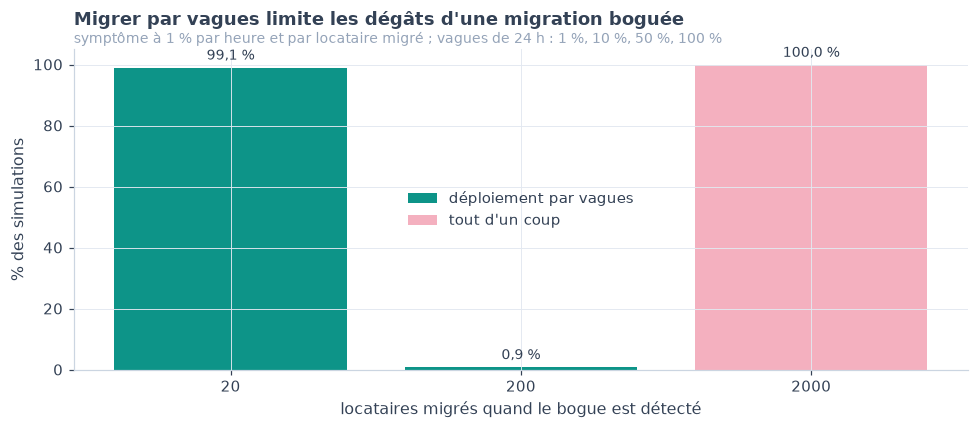

locataires touchés en moyenne : tout d'un coup 2000, par vagues 22


In [15]:
def rollout_exposed(waves, n_tenants=2_000, rate=0.01, step=24.0, n_runs=5_000, seed=0):
    """Nombre de locataires migrés au moment où le premier symptôme apparaît."""
    r = np.random.default_rng(seed)
    out = np.empty(n_runs)
    for k in range(n_runs):
        t_detect = np.inf
        exposed_at = np.ceil(np.array(waves) * n_tenants)
        t = 0.0
        for i, e in enumerate(exposed_at):
            dur = step if i < len(exposed_at) - 1 else np.inf
            wait = r.exponential(1 / (rate * e))            # premier symptôme parmi e locataires migrés
            if wait < dur:
                out[k] = e
                break
            t += dur
    return out

big_bang = rollout_exposed([1.0])
vagues = rollout_exposed([0.01, 0.10, 0.50, 1.0])

fig, ax = plt.subplots(figsize=(9, 4))
vals, cnt = np.unique(vagues, return_counts=True)
ax.bar([f"{v:.0f}" for v in vals], cnt / cnt.sum() * 100, color=TEAL, label="déploiement par vagues")
ax.bar([f"{big_bang[0]:.0f}"], [100], color=ROSE, alpha=0.35, label="tout d'un coup")
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.1f} %".replace(".", ",") for v in cont.datavalues], fontsize=9, padding=3)
ax.set_xlabel("locataires migrés quand le bogue est détecté")
ax.set_ylabel("% des simulations")
ax.set_title("Migrer par vagues limite les dégâts d'une migration boguée")
subtitle(ax, "symptôme à 1 % par heure et par locataire migré ; vagues de 24 h : 1 %, 10 %, 50 %, 100 %")
ax.legend(loc="center")
plt.tight_layout(); plt.show()
print(f"locataires touchés en moyenne : tout d'un coup {big_bang.mean():.0f}, par vagues {vagues.mean():.0f}")

Avec 20 locataires migrés dans la première vague, le taux de symptôme cumulé est de 0,2
par heure : le bogue est repéré dans les 24 premières heures dans 99 % des cas, après
n'avoir touché que 1 % des clients. La contrepartie, que le livre signale : la base vit
pendant plusieurs jours avec **deux versions du schéma**, et une opération qui
concernerait plusieurs locataires à la fois ne peut pas être transactionnelle d'un bout
à l'autre de la migration.

> **À retenir.** Un shard par locataire est une unité d'administration : on le
> sauvegarde, le restaure, l'exporte, l'efface, le place dans une région et le migre
> indépendamment des autres.